# 01 — Pressure: who needs staff, where, and how much

**Goal (PROBLEM.md):** before any forecasting, establish *the inventory position* of every
unit — a unit being one `(hospital, department)` queue.

The RTT data is an inventory system per unit per month:

| inventory concept | field | meaning |
|---|---|---|
| stock on hand | `Part_2` | **patients currently waiting** |
| stock ageing | waiting bands | 0-18w / 18-52w / >52w |
| inflow | `Part_3` | new referrals arriving |
| outflow | `Part_1A + Part_1B` | patients treated = capacity delivered |
| stockout | breach of 18 weeks | the NHS constitutional failure |

Status rule (thresholds from the NHS constitution, stated not tuned):
**GREEN** = at most 8% of waiters past 18 weeks · **RED** = misses that standard **and** the
queue is growing (3-month mean inflow > outflow) · **AMBER** = misses it but the queue is shrinking.

Staffing is expressed in WTE via the stated planning assumption `SLOTS_PER_WTE = 200`
appointments/month. This is a **single global divisor**: every ranking and funding decision is
computed in appointment-slots and only *displayed* in WTE, so all decisions are invariant to it.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SLOTS_PER_WTE = 200   # stated planning assumption; a pure display divisor (see header)

long = pd.read_csv("../data/processed/rtt_long_national.csv")
net = json.load(open("../config/nhs_network_national.json"))
region_of = {t["code"]: r["region"] for r in net["regions"] for t in r["trusts"]}
icb_of = {t["code"]: t["icb"] for r in net["regions"] for t in r["trusts"]}

key = ["provider_code", "specialty_code", "month"]
ser = ["provider_code", "specialty_code"]
cnt = long.pivot_table(index=key, columns="part", values="total_all", aggfunc="sum")
w = pd.DataFrame({"demand": cnt["Part_3"], "backlog": cnt["Part_2"],
                  "throughput": cnt["Part_1A"].fillna(0) + cnt["Part_1B"].fillna(0)}).reset_index()
bands = long[long["part"] == "Part_2"].groupby(key)[["weeks_0_18", "weeks_18_52", "weeks_52_plus"]].sum()
w = w.merge(bands.reset_index(), on=key, how="left").fillna(0)

banded = (w["weeks_0_18"] + w["weeks_18_52"] + w["weeks_52_plus"]).clip(lower=1)
w["share18"] = (w["weeks_18_52"] + w["weeks_52_plus"]) / banded
w["share52"] = w["weeks_52_plus"] / banded
w["region"] = w["provider_code"].map(region_of)
w["icb"] = w["provider_code"].map(icb_of)

# keep complete units (demand > 0 every month) - same completeness principle as trust selection
months = sorted(w["month"].unique())
ok = w[w["demand"] > 0].groupby(ser)["month"].nunique()
w = w.set_index(ser).loc[ok[ok == len(months)].index].reset_index()
w = w.sort_values(ser + ["month"]).reset_index(drop=True)

w["netflow3"] = w.groupby(ser, sort=False)["demand"].transform(lambda s: s.rolling(3).mean()) - \
                w.groupby(ser, sort=False)["throughput"].transform(lambda s: s.rolling(3).mean())
w["red"] = (w["share18"] > 0.08) & (w["netflow3"] > 0)
w["flag"] = np.where(w["share18"] <= 0.08, "GREEN", np.where(w["netflow3"] > 0, "RED", "AMBER"))

w.to_csv("../data/processed/ops_panel_national.csv", index=False)
LAST = months[-1]
print(f"ops panel: {w.groupby(ser).ngroups:,} units x {len(months)} months | "
      f"{w['provider_code'].nunique()} clients | latest {LAST}")

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
})

ops panel: 2,076 units x 60 months | 138 clients | latest 2026-03


flag
RED      1344
AMBER     511
GREEN     221


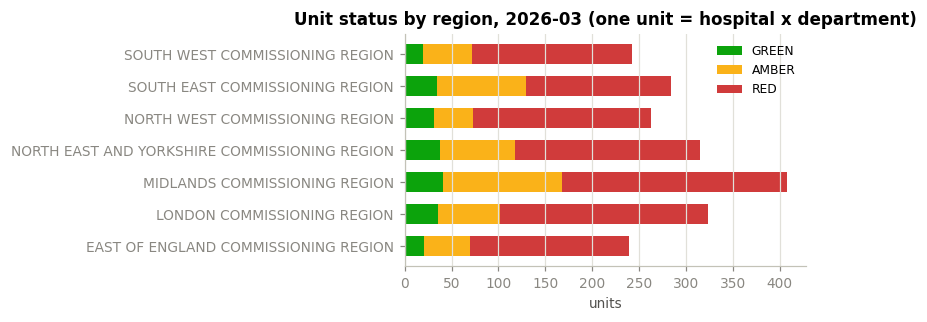

In [2]:
# the current pressure map
cur = w[w["month"] == LAST]
print(cur["flag"].value_counts().to_string())

STATUS = {"GREEN": "#0ca30c", "AMBER": "#fab219", "RED": "#d03b3b"}
byreg = cur.groupby(["region", "flag"]).size().unstack(fill_value=0).reindex(
    columns=["GREEN", "AMBER", "RED"], fill_value=0)
fig, ax = plt.subplots(figsize=(7.5, 3))
left = np.zeros(len(byreg))
for flag in ["GREEN", "AMBER", "RED"]:
    ax.barh(byreg.index, byreg[flag], left=left, color=STATUS[flag], height=0.6, label=flag)
    left += byreg[flag].values
ax.set_title(f"Unit status by region, {LAST} (one unit = hospital x department)")
ax.set_xlabel("units")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

In [3]:
# the staffing headline: shortfall if recent demand persists (6-month means, RED units)
g6 = w[w["month"].isin(months[-6:])].groupby(ser)[["demand", "throughput"]].mean()
g6["gap"] = (g6["demand"] - g6["throughput"]).clip(lower=0)
red_now = cur[cur["flag"] == "RED"].set_index(ser).index
gap_red = g6.loc[g6.index.isin(red_now), "gap"]
print(f"RED units: {len(red_now):,} | with positive 6-month gap: {(gap_red > 0).sum():,}")
print(f"national shortfall at current demand: {gap_red.sum():,.0f} slots/month "
      f"= {gap_red.sum() / SLOTS_PER_WTE:,.0f} WTE")

# client size distribution - the stratification axis pre-registered for the model comparison
size = w.groupby("provider_code")[ "specialty_code"].nunique()
band = pd.cut(size, [0, 4, 14, 23], labels=["small (<5 depts)", "medium (5-14)", "large (15+)"])
print("\nclient size bands (pre-registered stratification):")
print(band.value_counts().reindex(["small (<5 depts)", "medium (5-14)", "large (15+)"]).to_string())

RED units: 1,344 | with positive 6-month gap: 1,282
national shortfall at current demand: 214,949 slots/month = 1,075 WTE

client size bands (pre-registered stratification):
specialty_code
small (<5 depts)     21
medium (5-14)        14
large (15+)         103
